Step 1 — Load and inspect the dataset
Open your Python environment or Jupyter Notebook and make sure Dataset 2 is available. Run the following code.

In [3]:
import pandas as pd

# Load the CareFlow dataset
df = pd.read_csv("Careflowdataset.csv")

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

Dataset shape: (9855, 9)

Columns:
['Case ID', 'Event Index', 'Activity', 'Timestamp', 'Next Activity', 'Elapsed to Next (min)', 'Resource', 'Department', 'Status']

First 5 rows:
         Case ID  Event Index                      Activity  \
0  PAT-2026-9840            1      ED Registration & Triage   
1  PAT-2026-9840            2  Initial Physician Assessment   
2  PAT-2026-9840            3  Stat Blood Draw & Biomarkers   
3  PAT-2026-9644            1      ED Registration & Triage   
4  PAT-2026-9644            2  Initial Physician Assessment   

                  Timestamp                    Next Activity  \
0  2026-09-12T08:00:00.000Z     Initial Physician Assessment   
1  2026-09-12T08:10:00.000Z     Stat Blood Draw & Biomarkers   
2  2026-09-12T08:25:00.000Z  Central Laboratory Specimen Run   
3  2026-09-12T08:28:00.000Z     Initial Physician Assessment   
4  2026-09-12T08:52:00.000Z     Stat Blood Draw & Biomarkers   

   Elapsed to Next (min)                 Resource       

Step 2 — Verify event ordering
We need to check whether each patient's events are ordered correctly by Event Index, and whether their timestamps are chronological.

How to interpret the results:
- Duplicate event indices should be investigated.
- Out-of-order timestamps should be investigated.
- A zero result for both checks is a good sign, but it doesn't by itself prove that the entire event log is correct.

In [4]:
# Sort events within each patient case
df = df.sort_values(
    by=["Case ID", "Event Index"]
).reset_index(drop=True)

# Check for duplicate event indices within a case
duplicate_events = df.duplicated(
    subset=["Case ID", "Event Index"],
    keep=False
)

print("Rows with duplicate event indices:",
      duplicate_events.sum())

# Check whether timestamps are chronological within each case
df["Timestamp"] = pd.to_datetime(df["Timestamp"], utc=True)

timestamp_diff = (
    df.groupby("Case ID")["Timestamp"].diff()
)

out_of_order = timestamp_diff < pd.Timedelta(0)

print("Cases with out-of-order timestamps:",
      df.loc[out_of_order, "Case ID"].nunique())

print("Events with out-of-order timestamps:",
      out_of_order.sum())

Rows with duplicate event indices: 0
Cases with out-of-order timestamps: 0
Events with out-of-order timestamps: 0


Step 3 — Verify the activity sequence
Now we will compare the Next Activity column with the activity actually recorded in the next event.

In [5]:
# Get the next recorded activity within each case
df["Actual Next Activity"] = (
    df.groupby("Case ID")["Activity"].shift(-1)
)

# Compare the recorded next activity with the actual next event
has_next = df["Actual Next Activity"].notna()

matches = (
    df.loc[has_next, "Next Activity"]
    == df.loc[has_next, "Actual Next Activity"]
)

print("Events with a subsequent event:", has_next.sum())
print("Matching next activities:", matches.sum())
print("Mismatches:", (~matches).sum())

# Display mismatches for investigation
mismatches = df.loc[
    has_next & (df["Next Activity"] != df["Actual Next Activity"]),
    ["Case ID", "Event Index", "Activity",
     "Next Activity", "Actual Next Activity"]
]

print(mismatches.head(20))

Events with a subsequent event: 8427
Matching next activities: 8427
Mismatches: 0
Empty DataFrame
Columns: [Case ID, Event Index, Activity, Next Activity, Actual Next Activity]
Index: []


Step 4 — Display complete patient journeys
Let's create a readable activity sequence for each case.

In [6]:
journeys = (
    df.groupby("Case ID")["Activity"]
    .agg(list)
)

print("Sample patient journeys:\n")

for case_id, activities in journeys.head(10).items():
    print(f"{case_id}: {' -> '.join(activities)}")

Sample patient journeys:

PAT-2026-10000: ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Empiric Antibiotic / Targeted Therapy -> Inpatient Ward Bed Handover
PAT-2026-10001: ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Empiric Antibiotic / Targeted Therapy -> Inpatient Ward Bed Handover
PAT-2026-10002: ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Diagnostic CT / Angiography Imaging -> Sub-Specialist On-Call Consult -> Empiric Antibiotic / Targeted Therapy -> Direct ICU Bed Transfer
PAT-2026-10003: ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Empiric Antibiotic / Targeted Therapy -> Inpatient Ward Bed Handover
PAT-2026-10004: ED Registration & Triage -> Initial Physi

# Day 3: Exploratory Data Analysis

In [8]:
import pandas as pd

# Load the CareFlow dataset
df = pd.read_csv("/content/Careflowdataset.csv")

# Dataset overview
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nSummary statistics:")
display(df.describe(include="all").T)

Dataset shape: (9855, 9)

Column names:
['Case ID', 'Event Index', 'Activity', 'Timestamp', 'Next Activity', 'Elapsed to Next (min)', 'Resource', 'Department', 'Status']

Data types:
Case ID                   object
Event Index                int64
Activity                  object
Timestamp                 object
Next Activity             object
Elapsed to Next (min)    float64
Resource                  object
Department                object
Status                    object
dtype: object

Missing values per column:
Case ID                     0
Event Index                 0
Activity                    0
Timestamp                   0
Next Activity            1428
Elapsed to Next (min)    1428
Resource                    0
Department                  0
Status                      0
dtype: int64

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Case ID,9855,1428,PAT-2026-9308,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Event Index,9855.0,NaN,NaN,NaN,4.029731,2.114595,1.0,2.0,4.0,6.0,9.0
Activity,9855,11,Stat Blood Draw & Biomarkers,1600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Timestamp,9855,6500,2026-09-25T19:58:00.000Z,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Next Activity,8427,10,Stat Blood Draw & Biomarkers,1600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Elapsed to Next (min),8427.0,NaN,NaN,NaN,42.894268,26.789889,10.0,21.0,30.0,59.0,104.0
Resource,9855,15,Pathology Tech Kowalski,1600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department,9855,6,Emergency Medicine,4456,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Status,9855,9,Completed,4284,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# Count how often each activity occurs
activity_counts = df["Activity"].value_counts()

print("Activity Frequency:\n")
print(activity_counts)

Activity Frequency:

Activity
Stat Blood Draw & Biomarkers             1600
Central Laboratory Specimen Run          1600
ED Registration & Triage                 1428
Initial Physician Assessment             1428
Empiric Antibiotic / Targeted Therapy    1428
Inpatient Ward Bed Handover               819
Diagnostic CT / Angiography Imaging       571
Discharge to Outpatient Care              409
Sub-Specialist On-Call Consult            200
Direct ICU Bed Transfer                   200
Specimen Hemolysis / Re-draw Order        172
Name: count, dtype: int64


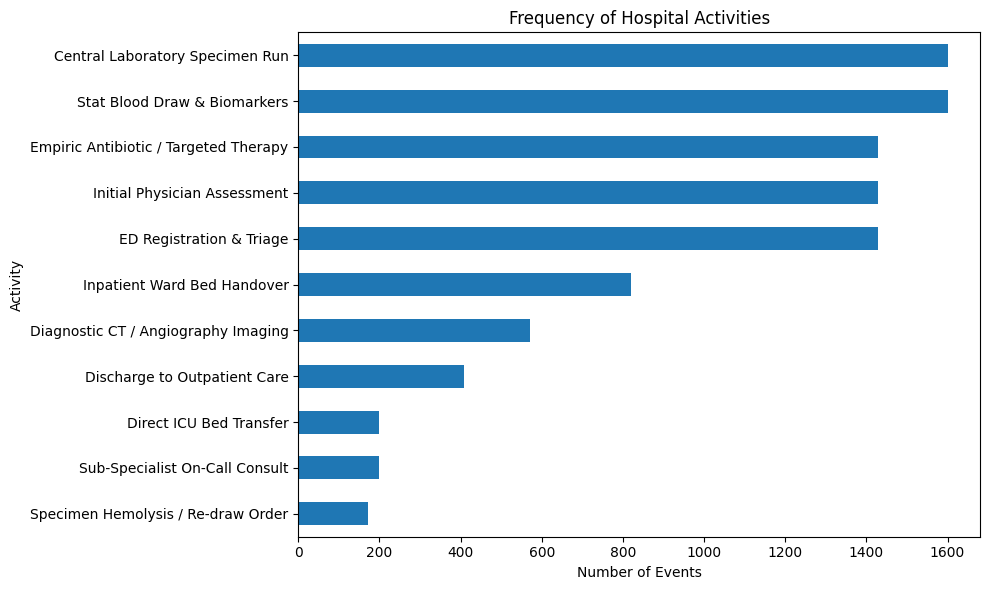

In [10]:
import matplotlib.pyplot as plt

activity_counts.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Frequency of Hospital Activities"
)

plt.xlabel("Number of Events")
plt.ylabel("Activity")
plt.tight_layout()
plt.show()

In [11]:
# Count the number of events in each patient case
events_per_case = df.groupby("Case ID")["Event Index"].count()

print("Events per patient case:")
print(events_per_case.describe())

print("\nNumber of events per case:")
print(events_per_case.value_counts().sort_index())

Events per patient case:
count    1428.000000
mean        6.901261
std         1.045254
min         6.000000
25%         6.000000
50%         7.000000
75%         8.000000
max         9.000000
Name: Event Index, dtype: float64

Number of events per case:
Event Index
6    685
7    371
8    200
9    172
Name: count, dtype: int64


In [12]:
# Sort events within each case
df_sorted = df.sort_values(
    ["Case ID", "Event Index"]
)

# Create one activity sequence per case
journeys = df_sorted.groupby("Case ID")["Activity"].agg(
    lambda activities: " -> ".join(activities)
)

# Count repeated journey patterns
journey_counts = journeys.value_counts()

print("Top 10 most common patient journeys:")
display(journey_counts.head(10).rename_axis("Patient Journey").reset_index(name="Case Count"))

Top 10 most common patient journeys:


,Patient Journey,Case Count
0,ED Registration & Triage -> Initial Physician ...,457
1,ED Registration & Triage -> Initial Physician ...,247
2,ED Registration & Triage -> Initial Physician ...,228
3,ED Registration & Triage -> Initial Physician ...,200
4,ED Registration & Triage -> Initial Physician ...,124
5,ED Registration & Triage -> Initial Physician ...,115
6,ED Registration & Triage -> Initial Physician ...,57


In [13]:
# Display complete journey patterns without truncation
pd.set_option("display.max_colwidth", None)

top_journeys = (
    journey_counts.head(10)
    .rename_axis("Patient Journey")
    .reset_index(name="Case Count")
)

display(top_journeys)


,Patient Journey,Case Count
0,ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Empiric Antibiotic / Targeted Therapy -> Inpatient Ward Bed Handover,457
1,ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Diagnostic CT / Angiography Imaging -> Empiric Antibiotic / Targeted Therapy -> Inpatient Ward Bed Handover,247
2,ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Empiric Antibiotic / Targeted Therapy -> Discharge to Outpatient Care,228
3,ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Diagnostic CT / Angiography Imaging -> Sub-Specialist On-Call Consult -> Empiric Antibiotic / Targeted Therapy -> Direct ICU Bed Transfer,200
4,ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Diagnostic CT / Angiography Imaging -> Empiric Antibiotic / Targeted Therapy -> Discharge to Outpatient Care,124
5,ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Specimen Hemolysis / Re-draw Order -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Empiric Antibiotic / Targeted Therapy -> Inpatient Ward Bed Handover,115
6,ED Registration & Triage -> Initial Physician Assessment -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Specimen Hemolysis / Re-draw Order -> Stat Blood Draw & Biomarkers -> Central Laboratory Specimen Run -> Empiric Antibiotic / Targeted Therapy -> Discharge to Outpatient Care,57


In [14]:
# Convert elapsed time to numeric, if necessary
df["Elapsed to Next (min)"] = pd.to_numeric(
    df["Elapsed to Next (min)"],
    errors="coerce"
)

# Overall summary of recorded transition durations
print("Transition-time summary:")
display(df["Elapsed to Next (min)"].describe())

# Average duration by activity
transition_summary = (
    df.dropna(subset=["Elapsed to Next (min)"])
      .groupby("Activity")["Elapsed to Next (min)"]
      .agg(["count", "mean", "median", "max"])
      .sort_values("mean", ascending=False)
)

print("\nTransition duration by current activity:")
display(transition_summary.round(2))

Transition-time summary:


,Elapsed to Next (min)
count,8427.000000
mean,42.894268
std,26.789889
min,10.000000
25%,21.000000
50%,30.000000
75%,59.000000
max,104.000000



Transition duration by current activity:


,count,mean,median,max
Activity,,,,
Empiric Antibiotic / Targeted Therapy,1428,89.44,89.0,104.0
Stat Blood Draw & Biomarkers,1600,49.31,48.0,59.0
Diagnostic CT / Angiography Imaging,571,43.98,31.0,88.0
Central Laboratory Specimen Run,1600,40.25,30.0,79.0
Sub-Specialist On-Call Consult,200,26.88,27.0,34.0
Specimen Hemolysis / Re-draw Order,172,25.00,25.0,25.0
Initial Physician Assessment,1428,21.99,22.0,29.0
ED Registration & Triage,1428,16.99,17.0,24.0


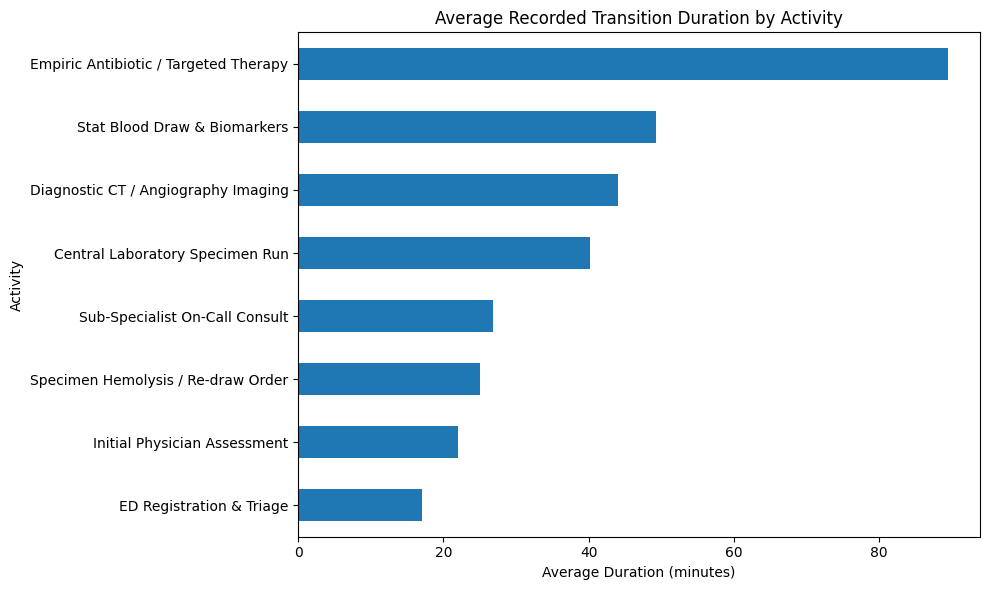

In [15]:
import matplotlib.pyplot as plt

transition_summary["mean"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Average Recorded Transition Duration by Activity"
)

plt.xlabel("Average Duration (minutes)")
plt.ylabel("Activity")
plt.tight_layout()
plt.show()